# Train and analyze relational bottleneck on transitive inference task in a manner like the RNN paper
The purpose of this notebook is to train a linear cross relational attention in a manner that is like the Kay et al RNN paper. Namely, let's make the first input the key and the second input the query.

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [2]:
torch.manual_seed(42)

## Build task

In [3]:
class TransitiveInferenceDataset(Dataset):
    def __init__(self, num_samples=1000, num_items=5, seed=42):
        """
        Transitive inference task:
        Items have a latent order A > B > C > D > E.
        The model sees pairs (x_i, x_j) and must predict whether x_i > x_j (label=1)
        or x_i < x_j (label=0).
        """
        self.num_samples = num_samples
        self.num_items = num_items
        self.rng = np.random.default_rng(seed)

        # Define latent ordering (A < B < C < D < E)
        self.ranks = torch.arange(num_items).float()

        # Define which pairs to use
        self._generate_pairs()

        # Generate balanced data
        self.data, self.labels = self._generate_data()

    def _generate_pairs(self):
        """Define possible pairs for training and testing."""
        self.positive_pairs = [(i, j) for i in range(self.num_items)
                                for j in range(self.num_items)
                                if j > i]  # strictly forward
        self.negative_pairs = [(j, i) for i in range(self.num_items)
                                for j in range(self.num_items)
                                if j > i]  # same but reversed

    def _generate_data(self):
        """Generate a balanced dataset of (pair, label) samples."""
        half = self.num_samples // 2
        X_pos = [self._make_sample(self.positive_pairs, label=1.0) for _ in range(half)]
        X_neg = [self._make_sample(self.negative_pairs, label=0.0) for _ in range(half)]
        X_all = X_pos + X_neg
        y_all = [1.0] * half + [0.0] * half

        # Shuffle consistently
        idxs = self.rng.permutation(self.num_samples)
        X_all = [X_all[i] for i in idxs]
        y_all = [y_all[i] for i in idxs]

        X_tensor = torch.stack([torch.stack(x) for x in X_all])  # (num_samples, 2, num_items)
        y_tensor = torch.tensor(y_all, dtype=torch.float32)
        return X_tensor, y_tensor

    def _make_sample(self, pair_list, label):
        """Pick a pair and convert to one-hot vectors."""
        i, j = pair_list[self.rng.integers(0, len(pair_list))]
        x_i = torch.nn.functional.one_hot(torch.tensor(i), num_classes=self.num_items).float()
        x_j = torch.nn.functional.one_hot(torch.tensor(j), num_classes=self.num_items).float()
        return [x_i, x_j]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

In [4]:
# Parameters
num_samples = 1000
num_items = 10

In [5]:
# Training task
dataset = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [6]:
dataset.data[0], dataset.labels[0]

(tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]]),
 tensor(1.))

## Design model

In [7]:
class RelationalAttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim):
        super().__init__()
        # Initialize weights
        self.W_q = nn.Linear(embed_dim, head_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, head_dim, bias=False)

    def forward(self, x_1, x_2):
        """
        x_1: (batch, embed_dim)
        x_2: (batch, embed_dim)
        returns: (batch, seq_len, head_dim)
        """
        Q = self.W_q(x_2)                            # (B, D)
        K = self.W_k(x_1)                            # (B, D)

        # Compute attention scores over the *learned* Value slots
        attn_weights = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

In [8]:
model = RelationalAttentionHead(num_items, 2)

## Train model

### Functions

In [9]:
def train_model(
    model,
    data_loader,
    optimizer=None,
    loss_fn=None,
    epochs=10,
    device=None,
    return_history=True,
    verbose=True,
):
    # Defaults
    device = device or next(model.parameters()).device
    optimizer = optimizer or torch.optim.Adam(model.parameters())
    loss_fn = loss_fn or torch.nn.BCEWithLogitsLoss()

    # Put model in training mode
    model.train()

    loss_history = []

    # Optionally wrap tqdm
    progress = range(epochs)
    if verbose:
        progress = tqdm(progress, desc="Training", total=epochs, leave=True)

    for epoch in progress:
        total_loss = 0.0

        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()

            preds = model(X[:,0:1,:], X[:,1:2,:])
            loss = loss_fn(preds, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(data_loader)
        loss_history.append(avg_loss)

        # Update progress bar if active
        if verbose:
            progress.set_postfix({"loss": f"{avg_loss:.4f}"})

    if verbose:
        progress.close()

    return loss_history if return_history else None


def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in loader:
            logits = model(X[:,0:1,:], X[:,1:2,:])
            preds = (torch.sigmoid(logits) > 0.5)

            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

### Training

In [10]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [11]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
loss = train_model(model, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:08<00:00, 61.93it/s, loss=0.0000]


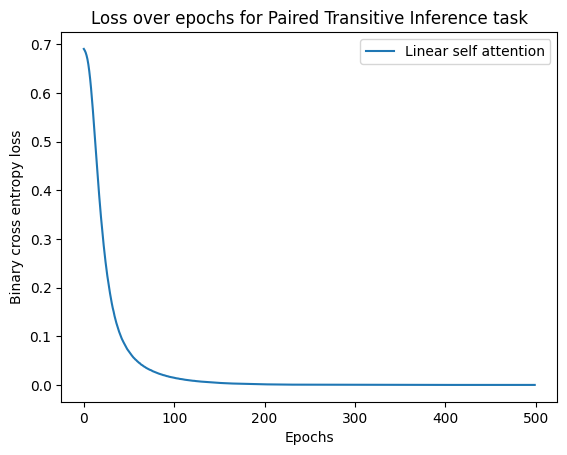

In [12]:
plt.plot(loss, label='Linear self attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for Paired Transitive Inference task')
plt.legend()
plt.show()

## Visualize learned weights

In [13]:
Q_weights = model.W_q.weight.data
K_weights = model.W_k.weight.data

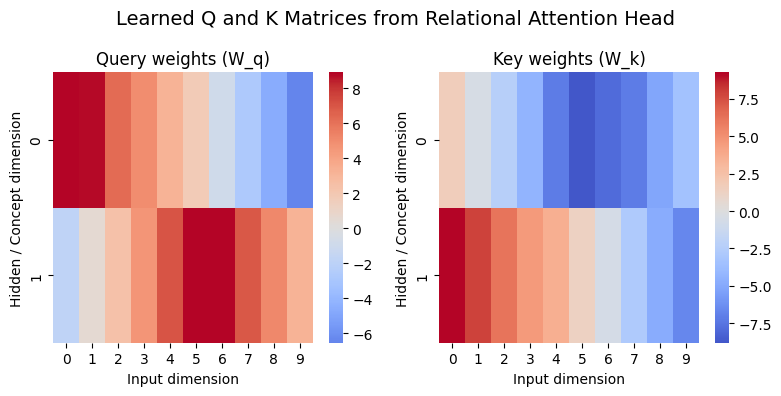

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Hidden / Concept dimension")

plt.suptitle("Learned Q and K Matrices from Relational Attention Head", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
def covariance(matrix):
    # subtract mean for proper covariance
    matrix_centered = matrix - matrix.mean(axis=0, keepdims=True)
    return np.cov(matrix_centered.T)  # (D, D)

In [16]:
cov_q = covariance(Q_weights)
cov_k = covariance(K_weights)

In [17]:
sim_qk = (Q_weights.T @ K_weights) / (K_weights.size(-1) ** 0.5)
sim_qk.shape

torch.Size([10, 10])

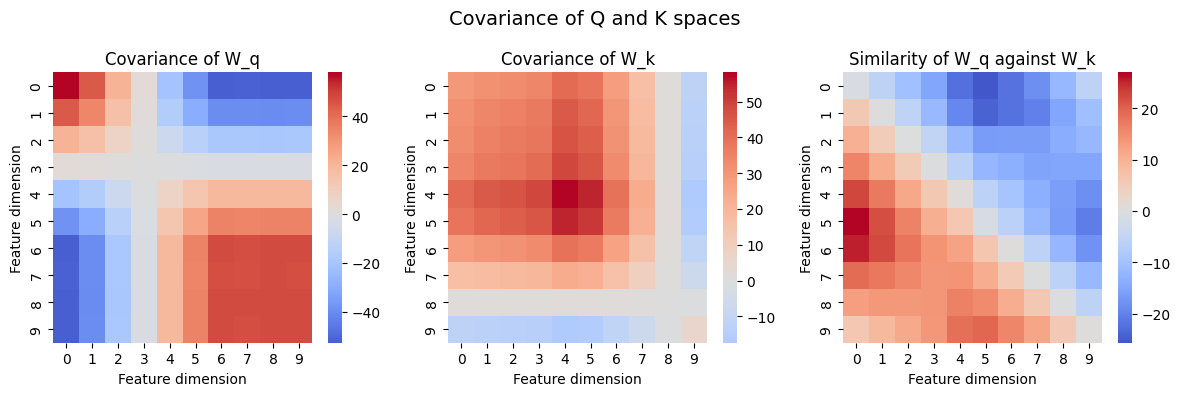

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(cov_q, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Covariance of W_q")

sns.heatmap(cov_k, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Covariance of W_k")

sns.heatmap(sim_qk, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Similarity of W_q against W_k")

for ax in axes:
    ax.set_xlabel("Feature dimension")
    ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q and K spaces", fontsize=14)
plt.tight_layout()
plt.show()

## Reverse engineer model

In [19]:
base = np.triu(np.ones((10,10)))
relational_table = base.T - base

In [20]:
relational_table

array([[ 0., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [ 1.,  0., -1., -1., -1., -1., -1., -1., -1., -1.],
       [ 1.,  1.,  0., -1., -1., -1., -1., -1., -1., -1.],
       [ 1.,  1.,  1.,  0., -1., -1., -1., -1., -1., -1.],
       [ 1.,  1.,  1.,  1.,  0., -1., -1., -1., -1., -1.],
       [ 1.,  1.,  1.,  1.,  1.,  0., -1., -1., -1., -1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  0., -1., -1., -1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  0., -1., -1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  0., -1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  0.]])

In [21]:
def transitive_inference(first, second):
    return relational_table[second, first].item()

In [22]:
transitive_inference(0,1)

1.0

In [23]:
transitive_inference(8,3)

-1.0